# 02. Entrenamiento: predecir las rentas del día siguiente
Versión basada en `train_by_day_seoul_bike.ipynb`. Compara **regresión lineal, Random Forest y Gradient Boosting** para pronosticar las **24 horas del día siguiente**, cuyo total se obtiene por suma.

**Diferencia principal:** además del día de semana, la fecha y la hora, utiliza demanda histórica: misma hora de ayer, de hace dos días y de hace una semana, más promedios de días previos. Nunca usa conteos del día objetivo ni clima observado futuro.

Se conserva el 65 % inicial para entrenamiento y el 35 % final para prueba, separando días completos. Los modelos se ajustan una sola vez con train. Durante prueba se actualiza el historial observado al avanzar cada día, **sin reentrenar los modelos**. Cada pronóstico usa registros hasta la víspera: esto simula predicciones sucesivas de un día, no una predicción de todo el 35 % emitida el primer día.

**Supuesto operativo:** a las 00:00 ya están disponibles los registros hasta las 23:00 del día anterior. Si llegan con retraso, habrá que desplazar los rezagos. Los ceros del archivo se conservan, pero se consideran registros ausentes según el EDA: ni etiquetas reales ni ceros de demanda para los rezagos.

## 0. Librerías

In [1]:
import os
import json
import hashlib
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.3f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25})


## 1. Configuración
Artefactos: `notebook/artifacts/02_Artifacts_prediction_by_next_day/`.
Se conservan los tres candidatos y los hiperparámetros del experimento anterior para comparar la nueva información de entrada. MLflow es opcional y está desactivado; el entrenamiento y los artefactos locales funcionan sin servidor.

In [2]:
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data/SeoulBikeData.csv").is_file()), None)
if RAIZ is None:
    raise FileNotFoundError("No se encuentra data/SeoulBikeData.csv")
cfg = {
    "train_size": .65,
    "test_size": .35,
    "semilla": 42,
    "objetivo": "alquileres",
    "horizonte_horas": 24,
    "registrar_mlflow": False,
    "experimento_mlflow": "seoul-bike-next-day",
    "candidatos": {
        "regresion_lineal": {},
        "random_forest": {"n_estimators": 200, "min_samples_leaf": 4,
                          "max_features": 1.0, "n_jobs": -1, "random_state": 42},
        "gradient_boosting": {"n_estimators": 200, "learning_rate": .05,
                              "max_depth": 3, "loss": "squared_error", "random_state": 42},
    },
}
SALIDAS = RAIZ / "notebook/artifacts/02_Artifacts_prediction_by_next_day"
SALIDAS.mkdir(parents=True, exist_ok=True)
DIAS = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
display(cfg)

{'train_size': 0.65,
 'test_size': 0.35,
 'semilla': 42,
 'objetivo': 'alquileres',
 'horizonte_horas': 24,
 'registrar_mlflow': False,
 'experimento_mlflow': 'seoul-bike-next-day',
 'candidatos': {'regresion_lineal': {},
  'random_forest': {'n_estimators': 200,
   'min_samples_leaf': 4,
   'max_features': 1.0,
   'n_jobs': -1,
   'random_state': 42},
  'gradient_boosting': {'n_estimators': 200,
   'learning_rate': 0.05,
   'max_depth': 3,
   'loss': 'squared_error',
   'random_state': 42}}}

## 2. Cargar datos y construir entradas disponibles al predecir
Se carga el CSV original y se reconstruye el timestamp. No hace falta ejecutar el EDA antes.

**Calendario conocido:** día de semana, hora, tendencia de fecha, ciclo anual e interacciones con fin de semana.
**Historial conocido hasta ayer:** rezagos horarios 24/48/168 h; promedio horario del día anterior y de los siete días anteriores. Los promedios diarios usan únicamente días con 24 registros; el de siete días requiere al menos tres días completos en esa ventana.
**Ausencias:** el CSV no se modifica. Se enmascaran como NaN en el historial y se imputan dentro del pipeline con medianas aprendidas solo de train y sus indicadores de ausencia. Las primeras filas pueden no tener historia suficiente.

No se aplica la media del mes posterior para humedad: usa futuro. Esta versión no usa meteorología, por lo que esa imputación retrospectiva del EDA no es necesaria.

In [3]:
ruta_csv = RAIZ / "data/SeoulBikeData.csv"
hash_csv = hashlib.sha256(ruta_csv.read_bytes()).hexdigest()
original = pd.read_csv(ruta_csv, encoding="utf-8")
requeridas = {"Date", "Hour", "Rented Bike Count"}
assert requeridas.issubset(original.columns), "Faltan columnas requeridas"
df = original[["Date", "Hour", "Rented Bike Count"]].rename(
    columns={"Date": "fecha", "Hour": "hora", "Rented Bike Count": "alquileres"}).copy()
df["fecha"] = pd.to_datetime(df.fecha, format="%d/%m/%Y", errors="raise")
assert df.hora.between(0, 23).all() and df.hora.mod(1).eq(0).all()
df["timestamp"] = df.fecha + pd.to_timedelta(df.hora, unit="h")
df = df.sort_values("timestamp").reset_index(drop=True)
assert df.timestamp.is_unique
assert df.alquileres.ge(0).all() and df.alquileres.mod(1).eq(0).all()
assert df[["fecha", "hora", "alquileres"]].notna().all().all()
esperadas = pd.date_range(df.timestamp.min(), df.timestamp.max(), freq="h")
assert pd.DatetimeIndex(df.timestamp).equals(esperadas), "Revisar horas faltantes"
df["registro_ausente"] = df.alquileres.eq(0)
ORIGEN_FECHA = df.fecha.min()
serie_observada = df.set_index("timestamp").alquileres.mask(df.set_index("timestamp").registro_ausente)

def crear_features(timestamps, historial=None):
    """Predicción a las 00:00: solo observaciones anteriores al día objetivo."""
    t = pd.Series(pd.to_datetime(timestamps)).reset_index(drop=True)
    historia = serie_observada if historial is None else historial
    historia = historia.sort_index()
    assert historia.index.is_unique
    x = pd.DataFrame(index=t.index)
    x["dia_semana"] = t.dt.dayofweek.astype(int)
    x["hora"] = t.dt.hour.astype(int)
    x["dias_desde_inicio"] = (t.dt.normalize() - ORIGEN_FECHA).dt.days
    angulo_anual = 2 * np.pi * (t.dt.dayofyear - 1) / 365.25
    x["fecha_sin"] = np.sin(angulo_anual)
    x["fecha_cos"] = np.cos(angulo_anual)
    fin_semana = t.dt.dayofweek.ge(5).astype(int)
    x["fin_semana_hora_sin"] = fin_semana * np.sin(2*np.pi*t.dt.hour/24)
    x["fin_semana_hora_cos"] = fin_semana * np.cos(2*np.pi*t.dt.hour/24)
    # Para cualquiera de las 24 horas, estos timestamps son anteriores al inicio del día.
    for h in [24, 48, 168]:
        fuentes = pd.DatetimeIndex(t - pd.Timedelta(hours=h))
        assert (fuentes < pd.DatetimeIndex(t.dt.normalize())).all()
        x[f"lag_{h}h"] = historia.reindex(fuentes).to_numpy()
    # Un total parcial no cuenta como un día completo observado.
    total_diario = historia.resample("D").sum(min_count=24)
    dias_objetivo = pd.DatetimeIndex(t.dt.normalize())
    x["media_horaria_dia_anterior"] = (
        total_diario.reindex(dias_objetivo - pd.Timedelta(days=1)).to_numpy() / 24)
    # Reindexar el calendario antes de rolling evita saltar días ausentes.
    calendario = pd.date_range(historia.index.min().normalize(),
                               max(historia.index.max().normalize(), dias_objetivo.max()), freq="D")
    total_diario = total_diario.reindex(calendario)
    ultimos_7 = total_diario.shift(1).rolling(7, min_periods=3).mean() / 24
    x["media_horaria_7dias_previos"] = ultimos_7.reindex(dias_objetivo).to_numpy()
    return x

CATEGORICAS = ["dia_semana", "hora"]
NUMERICAS = ["dias_desde_inicio", "fecha_sin", "fecha_cos",
             "fin_semana_hora_sin", "fin_semana_hora_cos",
             "lag_24h", "lag_48h", "lag_168h", "media_horaria_dia_anterior", "media_horaria_7dias_previos"]
FEATURES = CATEGORICAS + NUMERICAS
OBJETIVO = cfg["objetivo"]
print("Registros:", len(df), "| Objetivos ausentes:", df.registro_ausente.sum())
display(df.head())
display(crear_features(df.timestamp).head())

Registros: 8760 | Objetivos ausentes: 295


,fecha,hora,alquileres,timestamp,registro_ausente
0,2017-12-01,0,254,2017-12-01 00:00:00,False
1,2017-12-01,1,204,2017-12-01 01:00:00,False
2,2017-12-01,2,173,2017-12-01 02:00:00,False
3,2017-12-01,3,107,2017-12-01 03:00:00,False
4,2017-12-01,4,78,2017-12-01 04:00:00,False


,dia_semana,hora,dias_desde_inicio,fecha_sin,fecha_cos,fin_semana_hora_sin,fin_semana_hora_cos,lag_24h,lag_48h,lag_168h,media_horaria_dia_anterior,media_horaria_7dias_previos
0,4,0,0,-0.512,0.859,0.000,0.000,NaN,NaN,NaN,NaN,NaN
1,4,1,0,-0.512,0.859,0.000,0.000,NaN,NaN,NaN,NaN,NaN
2,4,2,0,-0.512,0.859,0.000,0.000,NaN,NaN,NaN,NaN,NaN
3,4,3,0,-0.512,0.859,0.000,0.000,NaN,NaN,NaN,NaN,NaN
4,4,4,0,-0.512,0.859,0.000,0.000,NaN,NaN,NaN,NaN,NaN


## 3. Partición: entrenamiento 65 % / prueba 35 %
Se ordenan los días y se asigna el primer 65 % a entrenamiento. Se redondea hacia abajo al día completo más próximo: esto evita cortar una jornada entre entrenamiento y prueba, aunque el porcentaje no sea exactamente 65,000 %.

La división se hace **antes** de excluir etiquetas ausentes. Las horas permanecen en el calendario y se predicen; solo se omiten del ajuste y del cálculo del error cuando no hay alquileres observados. No se hace estratificación ni mezcla aleatoria. Los hiperparámetros se fijan antes de mirar prueba.

In [4]:
dias = pd.Index(df.fecha.drop_duplicates())
n_dias_train = int(len(dias) * cfg["train_size"])
fecha_corte = dias[n_dias_train]
train_calendario = df.loc[df.fecha < fecha_corte].copy()
test_calendario = df.loc[df.fecha >= fecha_corte].copy()
train_df = train_calendario.loc[~train_calendario.registro_ausente].copy()
test_df = test_calendario.loc[~test_calendario.registro_ausente].copy()
assert train_calendario.timestamp.max() < test_calendario.timestamp.min()
assert set(train_df.fecha).isdisjoint(test_df.fecha)
assert len(train_calendario) + len(test_calendario) == len(df)

particion = pd.DataFrame([
    {"conjunto": nombre, "desde": calendario.timestamp.min(), "hasta": calendario.timestamp.max(),
     "dias": calendario.fecha.nunique(), "horas_calendario": len(calendario),
     "porcentaje_calendario": 100*len(calendario)/len(df),
     "etiquetas_observadas": len(observados), "horas_ausentes": calendario.registro_ausente.sum()}
    for nombre, calendario, observados in [
        ("train", train_calendario, train_df), ("test", test_calendario, test_df)]
])
display(particion)
X_train, y_train = crear_features(train_df.timestamp), train_df[OBJETIVO].reset_index(drop=True)
X_test, y_test = crear_features(test_df.timestamp), test_df[OBJETIVO].reset_index(drop=True)
print("Features:", FEATURES)
display(pd.crosstab(df.fecha.lt(fecha_corte).map({True:"train", False:"test"}), df.fecha.dt.dayofweek)
        .rename(columns=dict(enumerate(DIAS))))

,conjunto,desde,hasta,dias,horas_calendario,porcentaje_calendario,etiquetas_observadas,horas_ausentes
0,train,2017-12-01,2018-07-25 23:00:00,237,5688,64.932,5640,48
1,test,2018-07-26,2018-11-30 23:00:00,128,3072,35.068,2825,247


Features: ['dia_semana', 'hora', 'dias_desde_inicio', 'fecha_sin', 'fecha_cos', 'fin_semana_hora_sin', 'fin_semana_hora_cos', 'lag_24h', 'lag_48h', 'lag_168h', 'media_horaria_dia_anterior', 'media_horaria_7dias_previos']


fecha,Lunes,Martes,Miércoles,Jueves,Viernes,Sábado,Domingo
fecha,,,,,,,
test,432,432,432,456,456,432,432
train,816,816,816,792,816,816,816


### Control de disponibilidad de los datos
Se verifica que construir las entradas con la serie completa da exactamente el mismo resultado que usar solo registros anteriores al inicio del dia objetivo.

In [5]:
# Comprobar que eliminar todos los datos del dia objetivo y posteriores
# no modifica ninguna entrada de sus 24 pronosticos.
for dia in [fecha_corte, fecha_corte + pd.Timedelta(days=15), df.fecha.max()]:
    horas = pd.date_range(dia, periods=24, freq="h")
    historia_disponible = serie_observada.loc[serie_observada.index < dia]
    con_serie_completa = crear_features(horas, serie_observada)
    solo_pasado = crear_features(horas, historia_disponible)
    pd.testing.assert_frame_equal(con_serie_completa, solo_pasado)
assert list(X_train.columns) == FEATURES
assert X_train.index.equals(y_train.index)
assert not y_train.eq(0).any()
print("Verificado: las 24 entradas no dependen de registros del dia objetivo ni del futuro.")


Verificado: las 24 entradas no dependen de registros del dia objetivo ni del futuro.


## 4. Pipelines: imputación, preprocesado y tres regresores
Los rezagos pueden faltar por inicio de la serie o registros ausentes. `SimpleImputer` aprende medianas únicamente con train y añade indicadores. Después se escalan las numéricas y se codifican día de semana y hora con one-hot. Cada modelo usa las mismas filas observadas y variables.

Los conteos objetivo no se imputan. La salida se limita a cero para evitar rentas negativas; también se conservan las predicciones sin recortar.

In [6]:
preprocesado = ColumnTransformer([
    ("num", Pipeline([("imputacion", SimpleImputer(strategy="median", add_indicator=True)),
                      ("escalado", StandardScaler())]), NUMERICAS),
    ("cat", OneHotEncoder(categories=[list(range(7)), list(range(24))],
                          drop="first", handle_unknown="ignore",
                          sparse_output=False), CATEGORICAS),
])
estimadores = {
    "regresion_lineal": LinearRegression(**cfg["candidatos"]["regresion_lineal"]),
    "random_forest": RandomForestRegressor(**cfg["candidatos"]["random_forest"]),
    "gradient_boosting": GradientBoostingRegressor(**cfg["candidatos"]["gradient_boosting"]),
}
pipelines = {
    nombre: Pipeline([("preprocesado", clone(preprocesado)), ("modelo", estimador)])
    for nombre, estimador in estimadores.items()
}
display(pipelines["regresion_lineal"])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocesado', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers c

## 5. Entrenar
Los tres candidatos usan exactamente las mismas filas y variables. No se reentrenan con prueba ni se ajustan hiperparámetros usando sus resultados.

In [7]:
tiempos = {}
for nombre, pipeline in pipelines.items():
    inicio = time.perf_counter()
    pipeline.fit(X_train, y_train)
    tiempos[nombre] = time.perf_counter() - inicio
    print(f"{nombre}: entrenado en {tiempos[nombre]:.2f} s")

regresion_lineal: entrenado en 0.02 s


random_forest: entrenado en 1.22 s


gradient_boosting: entrenado en 1.84 s


## 6. Prueba: pronósticos sucesivos del día siguiente
Se evalúan modelos fijos en el 35 % final. Para cada día de prueba las entradas se construyen con historia anterior a sus 00:00. Los registros reales de un día de prueba pueden entrar en el historial de días **posteriores**, nunca en la predicción de ese mismo día.

Se comparan los modelos con referencias: promedio train, promedio día-hora train, misma hora de ayer y misma hora de la semana anterior. Las referencias con rezagos usan promedio día-hora train cuando falta historia. MAE/RMSE se expresan en rentas; R² puede ser negativo. Los totales diarios se evalúan solo con 24 etiquetas reales.

**No se optimizan hiperparámetros ni se ajusta el preprocesamiento con prueba.** Esta evaluación no es una predicción a varios meses de una sola vez.

In [8]:
def metricas_regresion(real, pred):
    return {"mae": float(mean_absolute_error(real, pred)),
            "rmse": float(np.sqrt(mean_squared_error(real, pred))),
            "r2": float(r2_score(real, pred))}

evaluacion = test_calendario[["timestamp", "fecha", "hora", OBJETIVO, "registro_ausente"]].reset_index(drop=True)
evaluacion["dia_semana"] = evaluacion.fecha.dt.dayofweek
X_test_completo = crear_features(evaluacion.timestamp)
media_global = float(y_train.mean())
media_dia_hora = train_df.assign(dia_semana=train_df.fecha.dt.dayofweek).groupby(
    ["dia_semana", "hora"])[OBJETIVO].mean()
indice_dia_hora = pd.MultiIndex.from_frame(evaluacion[["dia_semana", "hora"]])
predicciones = {
    "referencia_global": np.full(len(evaluacion), media_global),
    "referencia_dia_hora": media_dia_hora.reindex(indice_dia_hora).fillna(media_global).to_numpy(),
}
# Referencias disponibles al inicio del dia objetivo.
for nombre, columna in [("referencia_ayer", "lag_24h"), ("referencia_semana_anterior", "lag_168h")]:
    predicciones[nombre] = X_test_completo[columna].fillna(
        pd.Series(predicciones["referencia_dia_hora"])).to_numpy()
filas_metricas = []
observado = ~evaluacion.registro_ausente
for nombre, pipeline in pipelines.items():
    bruto = pipeline.predict(X_test_completo)
    evaluacion[f"{nombre}_sin_recorte"] = bruto
    predicciones[nombre] = np.maximum(bruto, 0)
for nombre, pred in predicciones.items():
    assert len(pred) == len(evaluacion) and np.isfinite(pred).all()
    evaluacion[nombre] = pred
    m = metricas_regresion(evaluacion.loc[observado, OBJETIVO], pred[observado])
    m.update({"modelo": nombre, "segundos_fit": tiempos.get(nombre, 0)})
    filas_metricas.append(m)
metricas_horarias = pd.DataFrame(filas_metricas).set_index("modelo").sort_values("mae")
display(metricas_horarias)

diario = evaluacion.groupby("fecha").agg(
    total_archivo=(OBJETIVO, "sum"), horas_observadas=("registro_ausente", lambda s: (~s).sum()))
for nombre in predicciones:
    diario[nombre] = evaluacion.groupby("fecha")[nombre].sum()
diario["dia_completo_observado"] = diario.horas_observadas.eq(24)
completos = diario.loc[diario.dia_completo_observado]
assert len(completos) >= 2
metricas_diarias = pd.DataFrame({
    nombre: metricas_regresion(completos.total_archivo, completos[nombre])
    for nombre in predicciones
}).T.sort_values("mae")
display(metricas_diarias)
print("Días de prueba:", len(diario), "| Días completos evaluables:", len(completos),
      "| Días con ausencia:", (~diario.dia_completo_observado).sum())
assert evaluacion.loc[observado, OBJETIVO].gt(0).all()


,mae,rmse,r2,segundos_fit
modelo,,,,
random_forest,232.263,364.566,0.633,1.219
referencia_ayer,257.779,429.439,0.490,0.000
gradient_boosting,260.771,376.293,0.609,1.844
referencia_semana_anterior,290.401,489.847,0.337,0.000
referencia_dia_hora,365.912,485.711,0.348,0.000
referencia_global,498.997,660.084,-0.204,0.000
regresion_lineal,598.229,758.782,-0.592,0.025


,mae,rmse,r2
referencia_ayer,"4,086.065","5,960.297",0.066
random_forest,"4,350.790","5,547.882",0.191
gradient_boosting,"4,878.882","6,106.335",0.020
referencia_semana_anterior,"5,957.412","8,165.952",-0.752
referencia_global,"7,715.845","8,977.182",-1.118
referencia_dia_hora,"7,720.874","9,002.029",-1.130
regresion_lineal,"13,562.743","15,728.572",-5.501


Días de prueba: 128 | Días completos evaluables: 117 | Días con ausencia: 11


### 6.1 Gráficos y errores por día de la semana
Se muestran los tres candidatos, no solo el de menor error. Las diferencias entre periodos pueden reflejar estación y clima no disponible en este modelo.

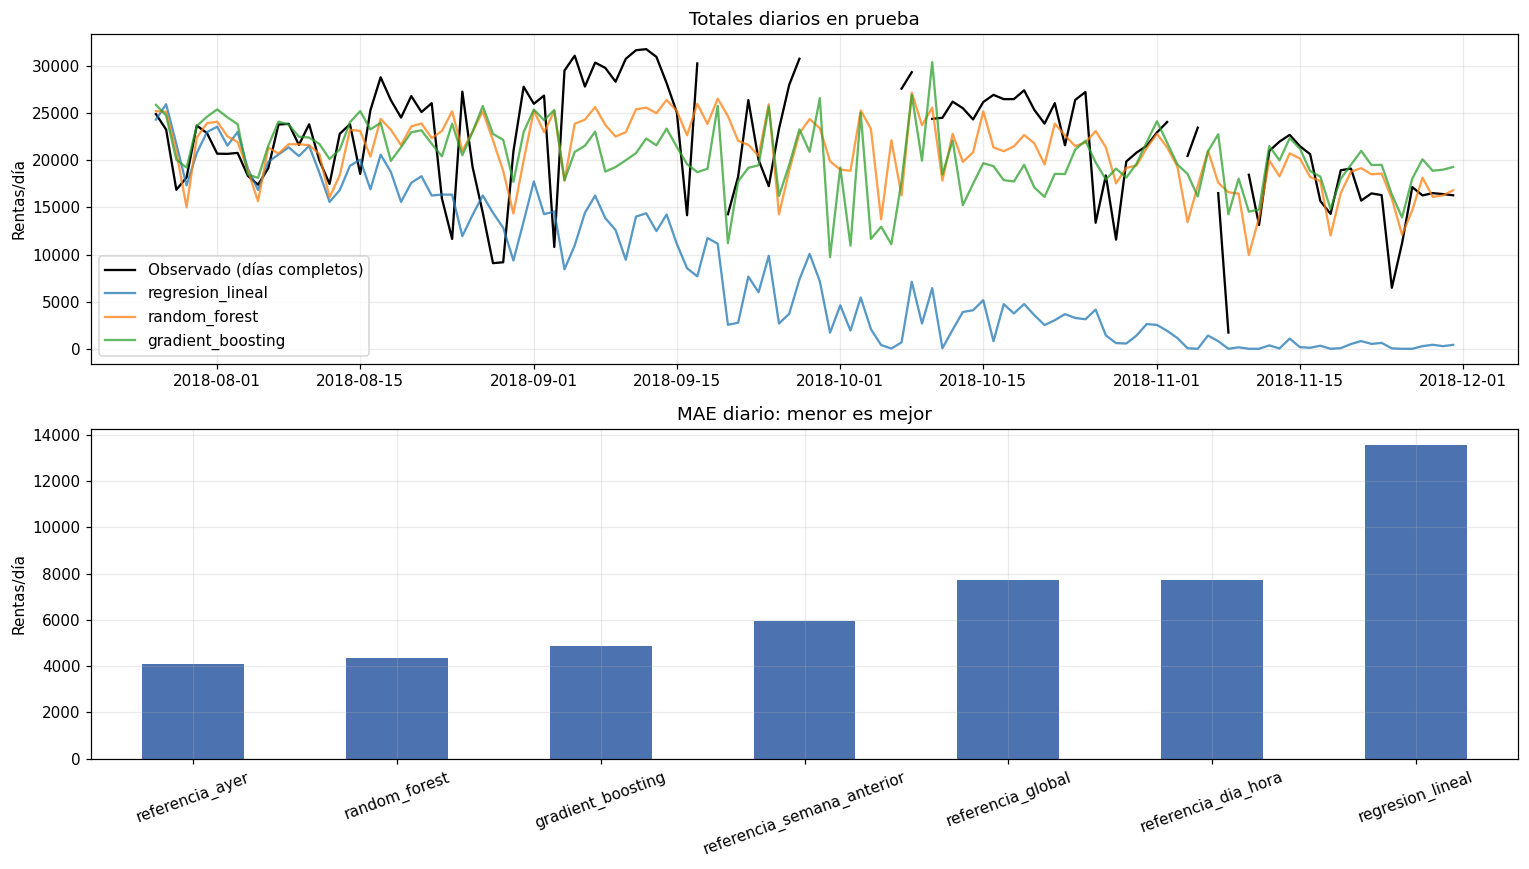

modelo,gradient_boosting,random_forest,regresion_lineal
grupo,,,
Lunes,294.625,259.143,662.927
Martes,267.300,235.570,637.677
Miércoles,269.572,215.360,654.929
Jueves,254.883,239.623,584.270
Viernes,254.295,233.018,533.338
Sábado,272.273,235.991,589.408
Domingo,212.158,205.770,528.882


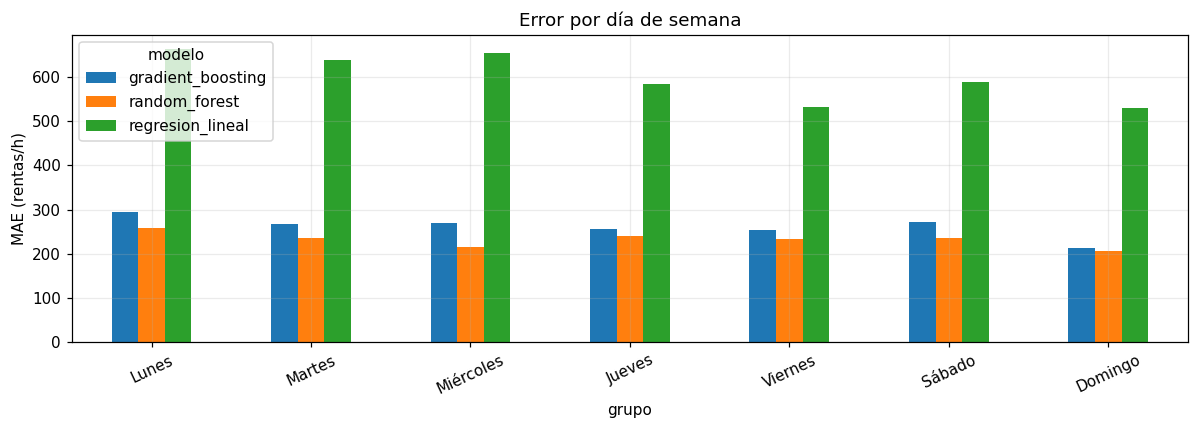

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))
real_diario = diario.total_archivo.where(diario.dia_completo_observado)
axes[0].plot(diario.index, real_diario, color="black", lw=1.5, label="Observado (días completos)")
for nombre in pipelines:
    axes[0].plot(diario.index, diario[nombre], alpha=.75, label=nombre)
axes[0].set(title="Totales diarios en prueba", ylabel="Rentas/día")
axes[0].legend()
metricas_diarias["mae"].plot.bar(ax=axes[1], color="#4C72B0")
axes[1].set(title="MAE diario: menor es mejor", ylabel="Rentas/día")
axes[1].tick_params(axis="x", rotation=20)
fig.tight_layout(); plt.show()

errores_grupo = []
for nombre in pipelines:
    e = evaluacion.loc[observado].copy()
    e["error_abs"] = (e[OBJETIVO] - e[nombre]).abs()
    for variable in ["dia_semana", "hora"]:
        t = e.groupby(variable).error_abs.agg(["size", "mean"]).reset_index()
        t.columns = ["grupo", "horas_observadas", "mae"]
        t["variable"], t["modelo"] = variable, nombre
        errores_grupo.append(t)
errores_segmentos = pd.concat(errores_grupo, ignore_index=True)
tabla_semana = errores_segmentos.query("variable == 'dia_semana'").pivot(
    index="grupo", columns="modelo", values="mae").rename(index=dict(enumerate(DIAS)))
display(tabla_semana)
ax = tabla_semana.plot.bar(figsize=(11,4), ylabel="MAE (rentas/h)", title="Error por día de semana")
plt.xticks(rotation=25); plt.tight_layout(); plt.show()


### 6.2 Dependencia del calendario
Se altera el grupo semanal o el grupo de fecha manteniendo los rezagos fijos, para medir el aumento de MAE. Es una aproximación descriptiva: combinaciones artificiales entre calendario e historial pueden quedar fuera de la distribución real. No es importancia causal ni una justificación para ajustar parámetros con prueba.

In [10]:
rng = np.random.default_rng(cfg["semilla"])
dias_test = pd.Index(evaluacion.fecha.drop_duplicates())
mapa_dia_fila = evaluacion.fecha.map(pd.Series(np.arange(len(dias_test)), index=dias_test)).to_numpy()
importancias = []
for nombre, pipeline in pipelines.items():
    mae_base = mean_absolute_error(evaluacion.loc[observado, OBJETIVO], predicciones[nombre][observado])
    for grupo in ["dia_semana", "fecha"]:
        aumentos = []
        for repeticion in range(5):
            orden = rng.permutation(len(dias_test))
            fechas_permutadas = pd.Series(dias_test[orden[mapa_dia_fila]]) + pd.to_timedelta(evaluacion.hora, unit="h")
            artificial = crear_features(fechas_permutadas)
            alterado = X_test_completo.copy()
            columnas = (["dia_semana", "fin_semana_hora_sin", "fin_semana_hora_cos"]
                        if grupo == "dia_semana" else ["dias_desde_inicio", "fecha_sin", "fecha_cos"])
            alterado[columnas] = artificial[columnas]
            pred = np.maximum(pipeline.predict(alterado), 0)
            aumentos.append(mean_absolute_error(evaluacion.loc[observado, OBJETIVO], pred[observado]) - mae_base)
        importancias.append({"modelo": nombre, "grupo": grupo,
                             "aumento_mae": np.mean(aumentos), "dispersion_repeticiones": np.std(aumentos)})
importancias_calendario = pd.DataFrame(importancias)
display(importancias_calendario)
print("La dispersión entre permutaciones no es un intervalo de confianza temporal.")


,modelo,grupo,aumento_mae,dispersion_repeticiones
0,regresion_lineal,dia_semana,-0.096,2.405
1,regresion_lineal,fecha,26.424,7.642
2,random_forest,dia_semana,11.367,1.189
3,random_forest,fecha,0.194,0.492
4,gradient_boosting,dia_semana,13.450,3.475
5,gradient_boosting,fecha,1.402,3.779


La dispersión entre permutaciones no es un intervalo de confianza temporal.


## 7. Artefactos locales y MLflow opcional
Se guardan los tres pipelines, configuración, métricas, predicciones, características de entrada y metadatos de horizonte y disponibilidad.

El pipeline recibe las FEATURES, no fechas sin preparar. Para inferencia deben reconstruirse con `crear_features(timestamps, historial)`, cargando `historial_observado.csv` y el origen de fecha documentado. Los archivos joblib corresponden al entrenamiento inicial del 65 %, sin reentrenamiento final.

MLflow sigue disponible con una bandera opcional. Registra las métricas de salidas recortadas y documenta ese postprocesamiento.

In [11]:
with open(SALIDAS / "config.json", "w", encoding="utf-8") as f:
    json.dump(cfg, f, ensure_ascii=False, indent=2)
metadatos = {
    "dataset_sha256": hash_csv, "origen_fecha": ORIGEN_FECHA.isoformat(),
    "features": FEATURES, "categoricas": CATEGORICAS, "numericas": NUMERICAS,
    "fecha_corte": fecha_corte.isoformat(), "horizonte_horas": 24,
    "origen_pronostico": "00:00 del dia objetivo; historial hasta las 23:00 del dia anterior",
    "imputacion": "mediana ajustada solo con train e indicadores de ausencia",
    "objetivo_ausente": "conteo original igual a cero",
    "prediccion": "maximum(pipeline.predict(crear_features(timestamps, historial)), 0)",
    "nota": "Calendario e historial previo al dia objetivo; evaluacion diaria sucesiva con modelos fijos.",
}
with open(SALIDAS / "metadatos.json", "w", encoding="utf-8") as f:
    json.dump(metadatos, f, ensure_ascii=False, indent=2)
for nombre, pipeline in pipelines.items():
    joblib.dump(pipeline, SALIDAS / f"{nombre}.joblib")
for nombre, tabla in {
    "metricas_horarias": metricas_horarias, "metricas_diarias": metricas_diarias,
    "particion": particion, "predicciones_horarias": evaluacion,
    "predicciones_diarias": diario, "errores_segmentos": errores_segmentos,
    "importancias_calendario": importancias_calendario,
}.items():
    tabla.to_csv(SALIDAS / f"{nombre}.csv", index=True)
# Verificar que persistir el modelo conserva sus predicciones.
for nombre in pipelines:
    recuperado = joblib.load(SALIDAS / f"{nombre}.joblib")
    np.testing.assert_allclose(recuperado.predict(X_test.head(24)), pipelines[nombre].predict(X_test.head(24)))
assert hashlib.sha256(ruta_csv.read_bytes()).hexdigest() == hash_csv
print("Artefactos guardados en:", SALIDAS)

# Entradas e historial para auditoria y reconstruccion de la inferencia.
X_train.to_csv(SALIDAS / "features_train.csv", index=False)
X_test_completo.to_csv(SALIDAS / "features_test.csv", index=False)
serie_observada.rename("alquileres_observados").to_csv(SALIDAS / "historial_observado.csv", index_label="timestamp")


Artefactos guardados en: C:\Users\segep\OneDrive\Documents\Personal\Maestria en Ciencia de Datos\Semestre 3\MLOps\Proyecto\proyecto_mlp_usta\notebook\artifacts\02_Artifacts_prediction_by_next_day


In [12]:
runs_mlflow = {}
if cfg["registrar_mlflow"]:
    import mlflow
    import mlflow.sklearn
    from mlflow.models import infer_signature
    mlflow.set_tracking_uri(os.environ.get("MLFLOW_TRACKING_URI", "http://localhost:5000"))
    mlflow.set_experiment(cfg["experimento_mlflow"])
    for nombre, pipeline in pipelines.items():
        with mlflow.start_run(run_name=nombre) as run:
            mlflow.log_params({"modelo": nombre, "train_size": cfg["train_size"],
                               "horizonte_horas": 24, "fecha_corte": str(fecha_corte),
                               "features": ",".join(FEATURES), **cfg["candidatos"][nombre]})
            mlflow.log_metrics({f"horario_{k}": float(metricas_horarias.loc[nombre, k])
                                for k in ["mae", "rmse", "r2"]})
            mlflow.log_metrics({f"diario_{k}": float(metricas_diarias.loc[nombre, k])
                                for k in ["mae", "rmse", "r2"]})
            mlflow.log_artifact(str(SALIDAS / "metadatos.json"))
            mlflow.log_artifact(str(SALIDAS / "predicciones_diarias.csv"))
            mlflow.sklearn.log_model(
                pipeline, name="model",
                signature=infer_signature(X_train.head(24), pipeline.predict(X_train.head(24))),
                input_example=X_train.head(3))
            mlflow.set_tag("postprocesamiento", "recortar predicciones negativas a cero antes de evaluar")
            runs_mlflow[nombre] = run.info.run_id
    display(runs_mlflow)
else:
    print("MLflow desactivado. Modelos y resultados disponibles como artefactos locales.")


MLflow desactivado. Modelos y resultados disponibles como artefactos locales.


## 8. Ejemplo real de inferencia: día posterior al final del archivo
Se pronostican las 24 horas del 01/12/2018 usando registros hasta el 30/11/2018. Los tres modelos siguen ajustados solo con el 65 % inicial; reciben historia reciente como entrada, sin reentrenarse con prueba. No existe una etiqueta en este CSV para evaluar ese día.

Para escoger otro día, cambie `dia_futuro` y proporcione historia observada hasta la víspera. Esto es un horizonte de un día; no se rellenan días de historia futura con valores reales desconocidos.

In [13]:
dia_futuro = df.fecha.max() + pd.Timedelta(days=1)
timestamps_futuros = pd.date_range(dia_futuro, periods=24, freq="h")
X_futuro = crear_features(timestamps_futuros, serie_observada)
pronostico = pd.DataFrame({"timestamp": timestamps_futuros,
                           "dia_semana": DIAS[dia_futuro.dayofweek]})
for nombre, pipeline in pipelines.items():
    pronostico[nombre] = np.maximum(pipeline.predict(X_futuro), 0)
display(pronostico)
totales_futuros = pronostico[list(pipelines)].sum().rename("rentas_dia_estimadas")
display(totales_futuros.to_frame())
assert len(pronostico) == 24 and pronostico.timestamp.dt.normalize().nunique() == 1
pronostico.to_csv(SALIDAS / "ejemplo_pronostico_24h.csv", index=False)


,timestamp,dia_semana,regresion_lineal,random_forest,gradient_boosting
0,2018-12-01 00:00:00,Sábado,0.000,482.133,637.252
1,2018-12-01 01:00:00,Sábado,0.000,489.241,625.061
2,2018-12-01 02:00:00,Sábado,0.000,300.330,445.315
3,2018-12-01 03:00:00,Sábado,0.000,221.411,373.551
4,2018-12-01 04:00:00,Sábado,0.000,154.365,278.614
5,2018-12-01 05:00:00,Sábado,0.000,136.557,257.480
6,2018-12-01 06:00:00,Sábado,0.000,190.920,287.983
7,2018-12-01 07:00:00,Sábado,0.000,583.213,464.365
8,2018-12-01 08:00:00,Sábado,0.000,863.663,731.063
9,2018-12-01 09:00:00,Sábado,0.000,690.006,609.443


,rentas_dia_estimadas
regresion_lineal,0.000
random_forest,"13,440.993"
gradient_boosting,"15,527.999"


## 9. Resumen y limitaciones

In [14]:
comparacion_candidatos = metricas_diarias.loc[list(pipelines)].sort_values("mae")
menor_error = comparacion_candidatos.index[0]
display(Markdown(
    f"**Menor MAE diario entre los tres candidatos en esta prueba:** {menor_error}.\n\n"
    f"- MAE diario: **{comparacion_candidatos.loc[menor_error, 'mae']:,.1f} rentas/día**.\n"
    f"- Días completos evaluados: {len(completos)} de {len(diario)}.\n"
    f"- Entrenamiento: {len(train_calendario)/len(df):.2%} del calendario; "
    f"prueba: {len(test_calendario)/len(df):.2%}.\n"
    f"- Etiquetas de entrenamiento: {len(train_df):,}; prueba: {len(test_df):,}.\n"
    f"- Resultados y pipelines: notebook/artifacts/02_Artifacts_prediction_by_next_day/."
))
display(comparacion_candidatos)


**Menor MAE diario entre los tres candidatos en esta prueba:** random_forest.

- MAE diario: **4,350.8 rentas/día**.
- Días completos evaluados: 117 de 128.
- Entrenamiento: 64.93% del calendario; prueba: 35.07%.
- Etiquetas de entrenamiento: 5,640; prueba: 2,825.
- Resultados y pipelines: notebook/artifacts/02_Artifacts_prediction_by_next_day/.

,mae,rmse,r2
random_forest,"4,350.790","5,547.882",0.191
gradient_boosting,"4,878.882","6,106.335",0.020
regresion_lineal,"13,562.743","15,728.572",-5.501


**Interpretación y limitaciones**
- Los rezagos añaden información de demanda reciente, además del día de semana; su utilidad se comprueba en las métricas, no se presupone.
- El escenario supone registros disponibles al finalizar cada día. No equivale a un pronóstico de todos los días de prueba desde un único origen.
- No se usan etiquetas ausentes para ajustar ni medir. Las referencias históricas también respetan las máscaras de ausencias.
- Aún no hay pronósticos meteorológicos, festivos o eventos operativos. Puede haber errores grandes ante cambios bruscos.
- Comparar con el notebook anterior requiere el mismo corte y la misma máscara de evaluación; aquí se mantienen.
- Solo hay un año y no se ha hecho búsqueda de hiperparámetros ni validación entre años. El mejor resultado de esta prueba no constituye una selección definitiva para producción.
- El CSV, el EDA y el notebook anterior se conservan. MLflow no se ejecuta por defecto.

### Resultado observado y comparación con una referencia sencilla
En esta ejecución, Random Forest obtuvo el menor MAE diario entre los tres modelos (**4.350,8 rentas/día; R² = 0,191**). Gradient Boosting obtuvo MAE **4.878,9** y R² **0,020**; regresión lineal, MAE **13.562,7** y R² **−5,501**.

La referencia “misma demanda que ayer” obtuvo un MAE diario menor (**4.086,1**), aunque Random Forest tuvo mejor RMSE (**5.547,9 frente a 5.960,3**). Por tanto, Random Forest reduce más los errores grandes, pero no mejora el error absoluto medio respecto a esa referencia. La elección debe considerar ambas métricas; todavía no se puede afirmar superioridad general.

Estas cifras corresponden a los artefactos de la ejecución guardada; al cambiar datos o parámetros, consultar las tablas recalculadas.